# EXP 11 : LOGISTIC REGRESSION AND K-NN

In [2]:
# Reading the csv file 
import pandas as pd 
from pandas import read_csv
# plotting the graph
from matplotlib import pyplot
# train test split 
from sklearn.model_selection import train_test_split
# Validation
from sklearn.model_selection import cross_val_score
# K-Fold
from sklearn.model_selection import StratifiedKFold
# Importing logistic regression --> sklearn
from sklearn.linear_model import LogisticRegression
# Importing KNN
from sklearn.neighbors import KNeighborsClassifier

In [7]:
path = "C:\\Users\\Student\\Downloads\\iris.csv"
names = ['sepal-length','sepal-width','petal-length','petal-width','class']
dataset = read_csv(path,names=names)
print(dataset)

     sepal-length  sepal-width  petal-length  petal-width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


In [9]:
# split the dataset into training and testing 
array = dataset.values 
X = array[:,0:4]
y = array[:,4]
# we are creating a training and validation set ---using--> train_test_split()
# test_size = 0.20 --> 20 % percent of data will be used as a test data
# random state = 1
# shuffle ----> shuffling the data 
X_train, X_validation, Y_train, Y_validation = train_test_split(X, y, test_size=0.20, random_state = 1, shuffle = True)

[('LR', LogisticRegression()), ('KNN', KNeighborsClassifier())]
LR:0.966667(0.040825)
KNN:0.958333(0.041667)


C:\Users\Student\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\Student\AppData\Local\Temp\ipykernel_3264\2689923006.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  pyplot.boxplot(result,labels = names)


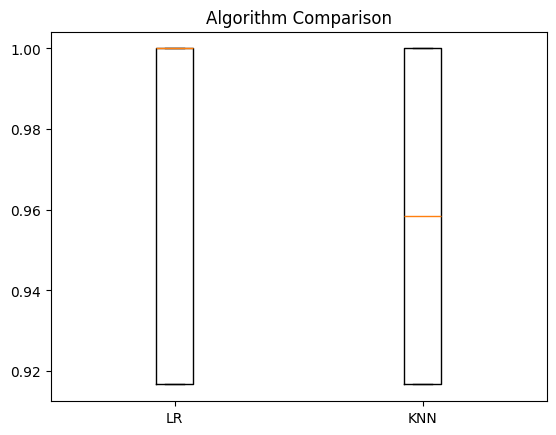

In [16]:
# Empty list for the models
models = []
models.append(('LR',LogisticRegression()))
models.append(('KNN',KNeighborsClassifier()))
print(models)
result = []
names = []
for name,model in models:
    kfold = StratifiedKFold(n_splits = 10, random_state = 1, shuffle = True)
    cv_result = cross_val_score(model,X_train,Y_train,cv=kfold,scoring='accuracy')
    result.append(cv_result)
    names.append(name)
    print('%s:%f(%f)'%(name,cv_result.mean(),cv_result.std()))

# Compare the algorithm
pyplot.boxplot(result,labels = names)
pyplot.title('Algorithm Comparison')
pyplot.show()

In [29]:
import math

X = [10, 20, 30, 40, 50, 60]
Y = [30, 12, 34, 32, 65, 50]

x = 34
y = 20

distance = []

print("E.D w.r.t 34 and 20")
for i in range(6):
    d = math.sqrt((X[i] - x) ** 2 + (Y[i] - y) ** 2)
    distance.append(d)

# Print distances
for i in range(6):
    print((X[i], Y[i]), "=", distance[i])

# Find 2 nearest points
for i in range(2):
    min_distance = min(distance)
    position = distance.index(min_distance)

    print("Nearest point:", (X[position], Y[position]))
    print("Distance:", min_distance)

    distance[position] = 9999


E.D w.r.t 34 and 20
(10, 30) = 26.0
(20, 12) = 16.1245154965971
(30, 34) = 14.560219778561036
(40, 32) = 13.416407864998739
(50, 65) = 47.75981574503821
(60, 50) = 39.698866482558415
Nearest point: (40, 32)
Distance: 13.416407864998739
Nearest point: (30, 34)
Distance: 14.560219778561036
